# STA 556 — Homework 2:

## 1. Imports and external data

In [11]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Allow Python to find the src folder
sys.path.insert(0, str(Path("..").resolve()))

# Import reusable functions
from src.sleep_utils import (
    load_data,
    clean_columns,
    filter_records,
    summarize_group,
    prepare_analysis
)

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the dataset 
data_path = Path("../data/Sleep_health_and_lifestyle_dataset.csv")

raw = load_data(data_path)

# Inspecting the dataset
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
print("Data types:", raw.dtypes)
print("Missing values:", raw.isna().sum())


raw.head()

Shape: (374, 13)
Columns: ['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps', 'Sleep Disorder']
Data types: Person ID                    int64
Gender                         str
Age                          int64
Occupation                     str
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                   str
Blood Pressure                 str
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder                 str
dtype: object
Missing values: Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category          

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 2. Modular cleaning

In [12]:
clean = prepare_analysis(raw)
print("Rows before cleaning:", len(raw))
print("Rows after cleaning:", len(clean))
print("Missing analysis variables:\n", clean[["sleep_duration", "quality_of_sleep", "stress_level"]].isna().sum())
clean.head()

Rows before cleaning: 374
Rows after cleaning: 374
Missing analysis variables:
 sleep_duration      0
quality_of_sleep    0
stress_level        0
dtype: int64


,person_id,gender,age,occupation,sleep_duration,quality_of_sleep,physical_activity_level,stress_level,bmi_category,blood_pressure,heart_rate,daily_steps,sleep_disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## 3. Exploratory analysis

In [13]:
print("Sleep duration summary (hours):")
print(clean["sleep_duration"].describe().round(2))
print("\nSleep quality by stress level:")
stress_summary = summarize_group(clean, "stress_level", "quality_of_sleep")
print(stress_summary.round(2).to_string(index=False))
correlation = clean["sleep_duration"].corr(clean["quality_of_sleep"])
print(f"\nPearson correlation: {correlation:.3f}")

Sleep duration summary (hours):
count    374.00
mean       7.13
std        0.80
min        5.80
25%        6.40
50%        7.20
75%        7.80
max        8.50
Name: sleep_duration, dtype: float64

Sleep quality by stress level:
 stress_level  count  mean  median
            3     71  8.97     9.0
            4     70  7.67     8.0
            5     67  7.90     8.0
            6     46  7.00     7.0
            7     50  6.00     6.0
            8     70  5.86     6.0

Pearson correlation: 0.883


**Question 1: How long do participants sleep?** The mean sleep duration is approximately **7.13 hours** and the median is **7.2 hours** (range 5.8–8.5 hours).

**Question 2: How does sleep quality differ by stress level?** Mean sleep quality is about **8.97** for stress level 3, compared with **5.86** for stress level 8. Quality generally declines at higher reported stress levels, though the pattern is not strictly monotonic.

**Question 3: Are sleep duration and sleep quality associated?** The Pearson correlation is approximately **0.883**, indicating a strong positive linear association in this dataset. This does not establish causality.

## 4. Visualization

### i. Figure 1: Distribution of sleep duration

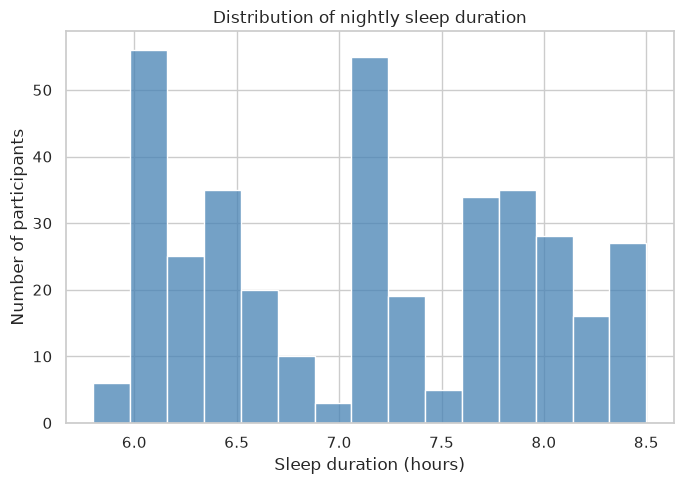

In [14]:
figure_path = Path("../figures/sleep_duration_distribution.png")

# Create histogram
fig, ax = plt.subplots(figsize=(7, 5))

sns.histplot(
    data=clean,
    x="sleep_duration",
    bins=15,
    color="steelblue",
    edgecolor="white",
    ax=ax
)

ax.set(
    title="Distribution of nightly sleep duration",
    xlabel="Sleep duration (hours)",
    ylabel="Number of participants"
)

fig.tight_layout()

# Saving figure
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

The observed range is 5.8 to 8.5 hours and most reported sleep durations cluster around seven to eight hours.

### ii. Figure 2: Sleep quality across stress levels

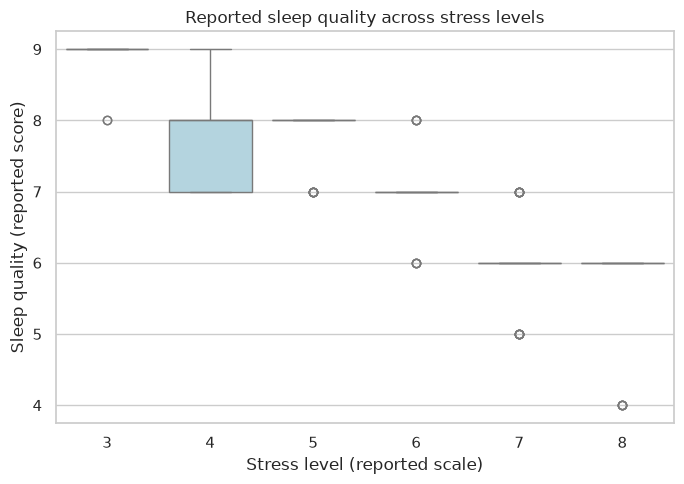

In [15]:
figure_path = Path("../figures/sleep_quality_by_stress.png")

# Creating boxplot
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(
    data=clean,
    x="stress_level",
    y="quality_of_sleep",
    color="lightblue",
    ax=ax
)

ax.set(
    title="Reported sleep quality across stress levels",
    xlabel="Stress level (reported scale)",
    ylabel="Sleep quality (reported score)"
)

fig.tight_layout()

# Save the figure
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

Participants reporting higher stress generally report lower sleep-quality scores; the chart also shows within-group variation.

### Figure 3: Relationship between sleep duration and quality

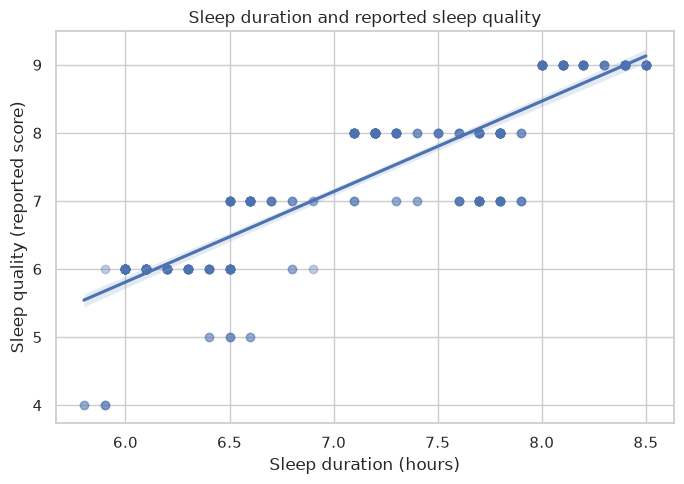

In [31]:
figure_path = Path("../figures/sleep_duration_vs_quality.png")

# Creating scatterplot with regression line
fig, ax = plt.subplots(figsize=(7, 5))

sns.regplot(
    data=clean,
    x="sleep_duration",
    y="quality_of_sleep",
    scatter_kws={"alpha": 0.35},
    ax=ax
)

ax.set(
    title="Sleep duration and reported sleep quality",
    xlabel="Sleep duration (hours)",
    ylabel="Sleep quality (reported score)"
)

fig.tight_layout()

# Save the figure
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

Longer reported sleep duration is strongly associated with higher sleep-quality scores (Pearson r ≈ 0.883). The fitted line is descriptive, not evidence of causation.